In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import numpy as np
from IPython.display import display, Math

A = np.array([[1.2345, 2, 3],
              [4, 5.6789, 6]])
d = 21
rng = (-1, 1)
dscrt = np.linspace(rng[0], rng[1], d)

# a random probability distribution
q = np.random.rand(d)

# make q to be decreasing to the index qq and the increasing afterwards
qq = 5
for i in range(qq):
    if i + 1 < d:
        q[i + 1] = min(q[i + 1], q[i])
for i in range(d - 1, qq, -1):
    if i - 1 >= 0:
        q[i - 1] = min(q[i - 1], q[i])
q /= q.sum()

q_mu = sum(q[i] * dscrt[i] for i in range(d))
# projection of q_mu is the closest point in dscrt to q_mu that has a smaller absolute value
q_mu_proj = min(dscrt, key=lambda x: abs(abs(x) - abs(q_mu)) if abs(x) <= abs(q_mu) else float('inf'))

print(f"q_mu: {q_mu}, q_mu_proj: {q_mu_proj}")

# the kernel matrix
# first let I(x) be the number of points between x and q_mu_proj (inclusive)
# then T(x | y) = 1 / I(y) if x is between y and q_mu_proj (inclusive), else 0
T = np.zeros((d, d))
for i in range(d):
    y = dscrt[i]
    if y <= q_mu_proj:
        indices = [j for j in range(d) if dscrt[j] >= y and dscrt[j] <= q_mu_proj]
    else:
        indices = [j for j in range(d) if dscrt[j] <= y and dscrt[j] >= q_mu_proj]
    I_y = len(indices)
    for j in indices:
        T[j, i] = 1 / I_y

P = T @ q
print(f"P sum: {P.sum()} (should be 1.0)")

T_show = r"\begin{pmatrix}" + \
        r"\\".join(
            " & ".join(f"{x:.3g}" for x in row) for row in T
        ) + \
        r"\end{pmatrix}"

display(Math(T_show))
print(dscrt)

q_mu: -0.11938352588937245, q_mu_proj: 0.10000000000000009
P sum: 0.9999999999999999 (should be 1.0)


<IPython.core.display.Math object>

[-1.  -0.9 -0.8 -0.7 -0.6 -0.5 -0.4 -0.3 -0.2 -0.1  0.   0.1  0.2  0.3
  0.4  0.5  0.6  0.7  0.8  0.9  1. ]


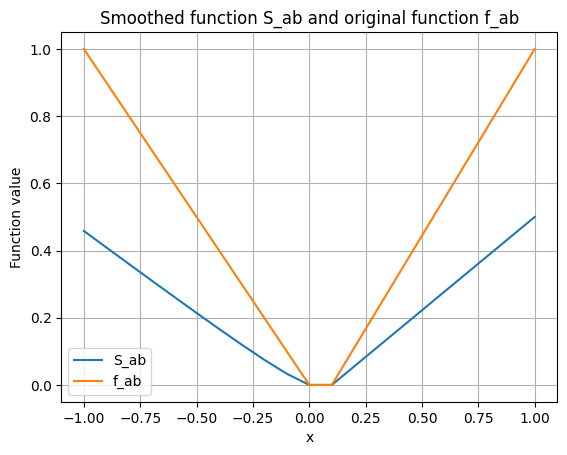

In [3]:
# Now we create a piecewise linear function on the net of dscrt points
# for two indices a <= b, we let the function f_ab be 1 at dscrt[0], 0 at dscrt[a] and dscrt[b], and 1 at dscrt[-1],
# and linear in between
# we can represent this function as a vector of length d
f_ab = np.zeros((d, d, d))  # list of all f_ab functions
for a in range(d):
    for b in range(a, d):
        f_ab[a, b, 0] = 1
        f_ab[a, b, a] = 0
        f_ab[a, b, b] = 0
        f_ab[a, b, -1] = 1
        # linear interpolation
        if a > 0:
            for i in range(1, a):
                f_ab[a, b, i] = 1 - (i / a)
        if b < d - 1:
            for i in range(b + 1, d - 1):
                f_ab[a, b, i] = (i - b) / (d - 1 - b)
        if b - a > 1:
            for i in range(a + 1, b):
                f_ab[a, b, i] = 0

# now we want to visualize the function S_ab = T^T f_ab
S_ab = np.zeros((d, d, d))
for a in range(d):
    for b in range(a, d):
        S_ab[a, b, :] = T.T @ f_ab[a, b, :]

a = 10
b = 11
# plot the smoothed function S_ab alongside f_ab for a , b
plt.plot(dscrt, S_ab[a, b, :], label="S_ab")
plt.plot(dscrt, f_ab[a, b, :], label="f_ab")
plt.xlabel("x")
plt.ylabel("Function value")
plt.title("Smoothed function S_ab and original function f_ab")
plt.grid()
plt.legend()
plt.show()

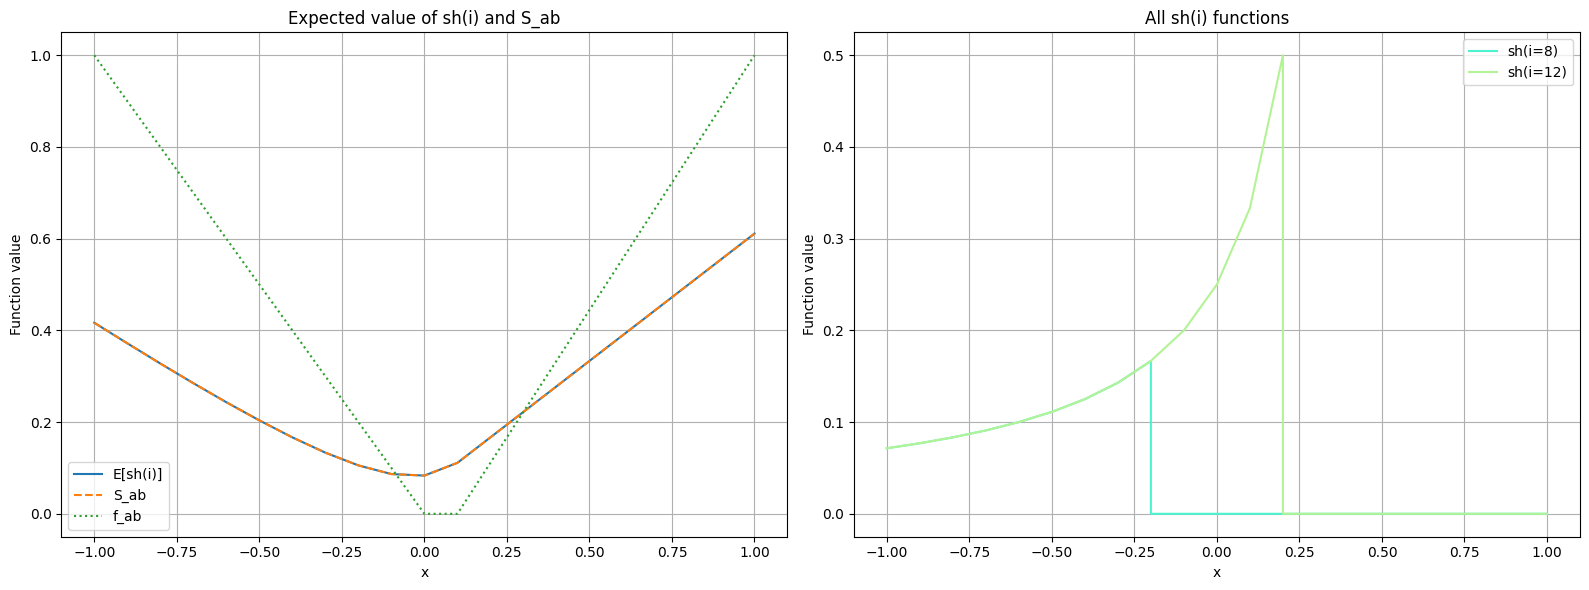

In [78]:
# plot the unbiased estimates of S_ab
# if we sample index i in dscrt according to distribution P,
# and sh(i) = T(i| \cdot) f_ab(i) / P(i),
# then E[sh(i)] = S_ab
sh = np.zeros((d, d, d, d))
for a in range(d):
    for b in range(a, d):
        for i in range(d):
            if P[i] > 0:
                sh[a, b, i, :] = T[i, :] * f_ab[a, b, i] / P[i]
            else:
                sh[a, b, i, :] = 0

# first plot the E[sh(i)] = S_ab for a = 10, b = 10
a = 10
b = 11
E_sh = np.zeros(d)
for i in range(d):
    E_sh += P[i] * sh[a, b, i, :]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Left plot: E[sh(i)] and S_ab
ax1.plot(dscrt, E_sh, label="E[sh(i)]")
ax1.plot(dscrt, S_ab[a, b, :], label="S_ab", linestyle='dashed')
ax1.plot(dscrt, f_ab[a, b, :], label="f_ab", linestyle='dotted')
ax1.set_xlabel("x")
ax1.set_ylabel("Function value")
ax1.set_title("Expected value of sh(i) and S_ab")
ax1.grid()
ax1.legend()

# Right plot: all sh(i)
colors = plt.cm.rainbow(np.linspace(0, 1, d))
count = 2
random_indices = np.random.permutation(d)
for i in random_indices:
    if sh[a, b, i, :].any():
        # ax2.plot(dscrt, sh[a, b, i, :], alpha=0.3, label=f"sh(i={i})", color=colors[i])
        # ax2.plot(dscrt, T[i], alpha=0.4, color=colors[i])
        # plot_with_jumps(dscrt, T.T[i], ax=ax2, alpha=0.3, label=f"sh(i={i})", color=colors[i])
        plot_with_jumps(dscrt, T[i], ax=ax2,
        # alpha=0.3,
        label=f"sh(i={i})", color=colors[i],)
        count -= 1
        if count == 0:
            break
        # ax2.plot(dscrt, T.T[i], alpha=0.4, color=colors[i])

ax2.set_xlabel("x")
ax2.set_ylabel("Function value")
ax2.set_title("All sh(i) functions")
ax2.grid()
ax2.legend()

plt.tight_layout()
plt.show()

In [8]:
def plot_with_jumps(x, y, ax=None, **kwargs):
    """
    Plot a function with vertical transitions to/from y=0.
    
    Parameters:
    - x: array-like, x coordinates
    - y: array-like, y values
    - ax: matplotlib axis (optional, uses plt if None)
    - **kwargs: additional arguments passed to plot()
    """
    x = np.asarray(x)
    y = np.asarray(y)
    
    x_plot = []
    y_plot = []
    
    for i in range(len(x)):
        if i == 0:
            x_plot.append(x[i])
            y_plot.append(y[i])
        else:
            # Check if transitioning to/from zero
            prev_zero = (y[i-1] == 0)
            curr_zero = (y[i] == 0)
            
            if prev_zero and not curr_zero:
                # Transition from 0 to non-zero: vertical line at current x
                x_plot.append(x[i])
                y_plot.append(0)
                x_plot.append(x[i])
                y_plot.append(y[i])
            elif not prev_zero and curr_zero:
                # Transition from non-zero to 0: vertical line at current x
                x_plot.append(x[i-1])
                y_plot.append(0)
                x_plot.append(x[i])
                y_plot.append(0)
            else:
                # Normal transition
                x_plot.append(x[i])
                y_plot.append(y[i])
    
    if ax is None:
        return plt.plot(x_plot, y_plot, **kwargs)
    else:
        return ax.plot(x_plot, y_plot, **kwargs)


/var/folders/2y/8rqh7kk566b1nf_453g9hx3w0000gn/T/ipykernel_45907/4040001674.py:9: RuntimeWarning: divide by zero encountered in scalar divide
  slope_i = 1 / (dscrt[i] - rng[0])


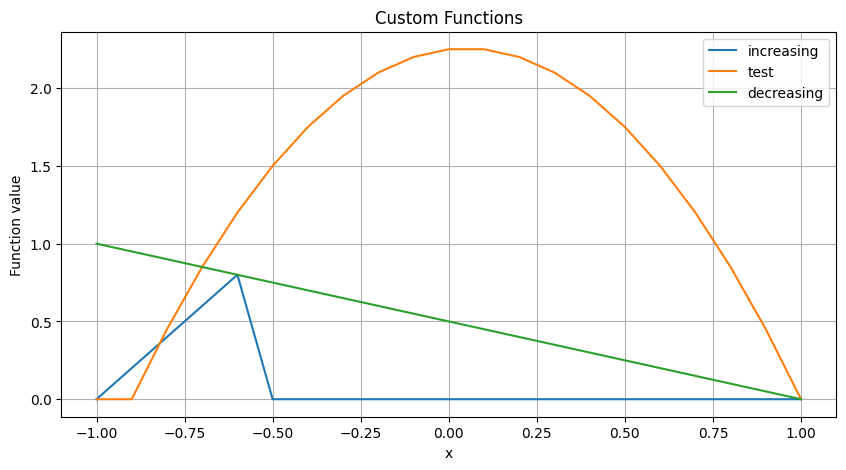

In [ ]:
# exploring other estimators
slope = 1/(rng[1] - rng[0])

inc = dscrt * slope + 1/2  # increasing function from -1 to 1
dec = -dscrt * slope + 1/2  # decreasing function from -1 to 1

G = np.zeros((d, d))
for i in range(d):
    slope_i = 1 / (dscrt[i] - rng[0])
    for j in range(i):
        nudge = dec[j] - slope_i * (dscrt[i] - dscrt[j])
        G[i, j] = nudge / dec[i] if dec[i] != 0 else 0




#plot the functions
# set figure size
plt.figure(figsize=(10, 5))
plt.plot(dscrt, G[5], label="increasing")
plt.plot(dscrt, test, label="test")
plt.plot(dscrt, dec, label="decreasing")
plt.xlabel("x")
plt.ylabel("Function value")
plt.title("Custom Functions")
plt.grid()
plt.legend()
plt.show()